In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

from statsforecast.models import Naive, SeasonalNaive

from src.forecasting.backtest import evaluate, run_statsforecast, summarise, train_part
from src.forecasting.data import to_nixtla

df = pd.read_parquet(ROOT / "data" / "processed" / "sales_long.parquet")
classes = pd.read_parquet(ROOT / "data" / "processed" / "item_classes.parquet")
train = train_part(to_nixtla(df))

ids = train["unique_id"].unique()[:40]  # só 40 produtos, para testar
res = run_statsforecast(
    [Naive(), SeasonalNaive(season_length=7)], train[train["unique_id"].isin(ids)]
)
summarise(evaluate(res, train, classes)).round(3)

,model,demand_class,mae,rmsse,bias,n_items
5,SeasonalNaive,all,1.941,1.012,-0.142,40
0,Naive,all,2.006,1.043,0.060,40
6,SeasonalNaive,erratic,4.197,0.871,-0.025,5
1,Naive,erratic,4.483,0.877,0.364,5
7,SeasonalNaive,intermittent,1.026,0.982,-0.140,24
2,Naive,intermittent,1.052,1.010,-0.026,24
8,SeasonalNaive,lumpy,2.708,0.989,-0.459,5
3,Naive,lumpy,2.771,1.092,-0.421,5
9,SeasonalNaive,smooth,3.081,1.271,-0.194,6
4,Naive,smooth,3.119,1.271,-0.055,6


Text(0.5, 0, 'Share of gain')

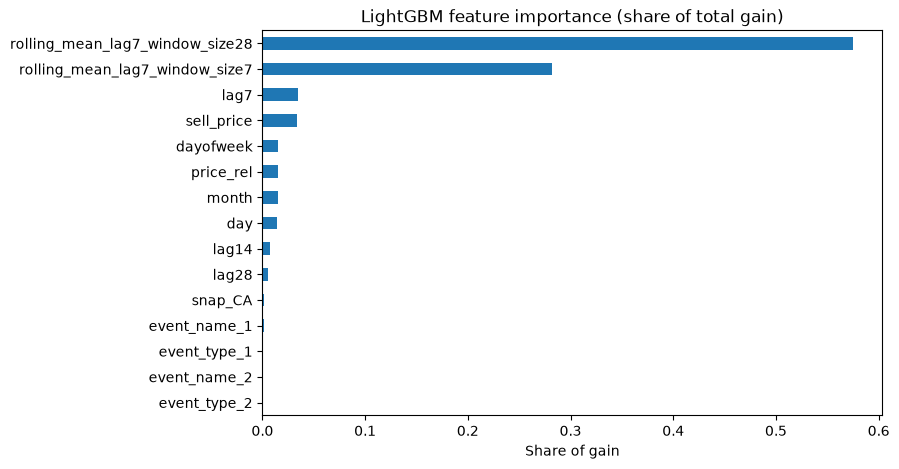

In [2]:
from src.forecasting.ml import add_ml_features, make_mlforecast

fcst = make_mlforecast()
fcst.fit(add_ml_features(train), static_features=[])

model = fcst.models_["LightGBM"]
importance = pd.Series(
    model.booster_.feature_importance(importance_type="gain"),
    index=model.booster_.feature_name(),
)
importance = (importance / importance.sum()).sort_values()

ax = importance.plot.barh(figsize=(8, 5), color="tab:blue")
ax.set_title("LightGBM feature importance (share of total gain)")
ax.set_xlabel("Share of gain")

O modelo depende sobretudo do nível recente de vendas (médias de 7 e 28 dias). O preço e o dia da semana ajudam pouco, e os eventos quase nada.

In [3]:
from src.forecasting.backtest import evaluate, run_mlforecast, summarise

trials = {
    "base (63 leaves, lr 0.05)": {},
    "31 leaves": {"num_leaves": 31},
    "127 leaves, 100 min samples": {"num_leaves": 127, "min_child_samples": 100},
    "lr 0.03, 800 trees": {"learning_rate": 0.03, "n_estimators": 800},
}

rows = []
for name, params in trials.items():
    res = run_mlforecast(make_mlforecast(**params), train)
    s = summarise(evaluate(res, train, classes)).set_index("demand_class")
    rows.append({"trial": name, **s["rmsse"].round(3).to_dict()})
    print(name, "done")

pd.DataFrame(rows).set_index("trial")

base (63 leaves, lr 0.05) done
31 leaves done
127 leaves, 100 min samples done
lr 0.03, 800 trees done


,all,erratic,intermittent,lumpy,smooth
trial,,,,,
"base (63 leaves, lr 0.05)",0.745,0.680,0.760,0.698,0.806
31 leaves,0.745,0.679,0.760,0.696,0.806
"127 leaves, 100 min samples",0.745,0.680,0.759,0.699,0.805
"lr 0.03, 800 trees",0.745,0.680,0.759,0.699,0.806


All four settings give RMSSE 0.745 overall, with differences of at most 0.002 per class.
The model is not sensitive to these parameters, so the base setting is kept.